# CNN Evaluation & Inference

This notebook uses the **already-trained `disease_cnn_30_epochs.pth`**.

**No training is performed here.** The exact crop-aware CNN architecture is reconstructed, the saved weights are loaded, validation/test performance is evaluated, errors are analysed, and a single-image inference function is provided.

## Project assumptions

- Local Windows + VS Code/Jupyter only.
- Project root: `D:\Intelligent_farming_system`
- Processed dataset: `disease_dataset\processed`
- Cached training/validation images were generated from the same provisional split used for training.
- The model is **crop-aware**: the crop label is supplied to the model and selects the corresponding disease head.
- The training-time random horizontal flip is **not** used during validation/test inference.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

import torch
import torch.nn as nn

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.14.0+cu130
CUDA available: True


In [2]:
# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(r"D:\Intelligent_farming_system")
DATASET_DIR = PROJECT_ROOT / "disease_dataset" / "processed"
CACHE_DIR = PROJECT_ROOT / "disease_detection" / "cache"
MODEL_PATH = PROJECT_ROOT / "disease_detection" / "models" / "disease_cnn_30_epochs.pth"

TRAIN_CACHE_PATH = CACHE_DIR / "train_images.npy"
VAL_CACHE_PATH = CACHE_DIR / "val_images.npy"

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_DIR)
print("Model:", MODEL_PATH)
print("Train cache exists:", TRAIN_CACHE_PATH.exists())
print("Validation cache exists:", VAL_CACHE_PATH.exists())
print("Model exists:", MODEL_PATH.exists())

assert DATASET_DIR.exists(), f"Dataset not found: {DATASET_DIR}"
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert VAL_CACHE_PATH.exists(), f"Validation cache not found: {VAL_CACHE_PATH}"


Project: D:\Intelligent_farming_system
Dataset: D:\Intelligent_farming_system\disease_dataset\processed
Model: D:\Intelligent_farming_system\disease_detection\models\disease_cnn_30_epochs.pth
Train cache exists: True
Validation cache exists: True
Model exists: True


In [3]:
# ============================================================
# DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce RTX 3050 A Laptop GPU


## Rebuild the exact dataset records and provisional split

The trained cache was built from these records, followed by the same two stratified `train_test_split` calls with `random_state=42`. Recreating this is important because the cache stores images by record index.

In [4]:
# ============================================================
# IMAGE RECORDS
# ============================================================

image_records = []

for crop_dir in DATASET_DIR.iterdir():
    if crop_dir.is_dir():
        for disease_dir in crop_dir.iterdir():
            if disease_dir.is_dir():
                for image_path in disease_dir.iterdir():
                    if image_path.is_file():
                        image_records.append(
                            (image_path, crop_dir.name, disease_dir.name)
                        )

print("Total image records:", len(image_records))
assert len(image_records) == 63664, (
    f"Expected 63664 processed images, found {len(image_records)}. "
    "Do not continue until the dataset matches the trained model's dataset."
)


Total image records: 63664


In [5]:
# ============================================================
# EXACT PROVISIONAL SPLIT USED BY THE TRAINING NOTEBOOK
# ============================================================

stratification_labels = [
    (crop, disease)
    for _, crop, disease in image_records
]

train_records, temp_records = train_test_split(
    image_records,
    test_size=0.3,
    random_state=42,
    stratify=stratification_labels,
)

temp_labels = [
    (crop, disease)
    for _, crop, disease in temp_records
]

val_records, test_records = train_test_split(
    temp_records,
    test_size=0.5,
    random_state=42,
    stratify=temp_labels,
)

print(f"Train:      {len(train_records)}")
print(f"Validation: {len(val_records)}")
print(f"Test:       {len(test_records)}")

assert len(train_records) == 44564
assert len(val_records) == 9550
assert len(test_records) == 9550


Train:      44564
Validation: 9550
Test:       9550


In [6]:
# ============================================================
# CROP / DISEASE MAPPINGS
# ============================================================

crops = sorted({
    crop
    for _, crop, _ in image_records
})

crop_to_index = {
    crop: index
    for index, crop in enumerate(crops)
}

index_to_crop = {
    index: crop
    for crop, index in crop_to_index.items()
}

disease_to_index = {}
index_to_disease = {}

for crop in crops:
    diseases = sorted({
        disease
        for _, record_crop, disease in image_records
        if record_crop == crop
    })

    disease_to_index[crop] = {
        disease: index
        for index, disease in enumerate(diseases)
    }

    index_to_disease[crop] = {
        index: disease
        for disease, index in disease_to_index[crop].items()
    }

print("Number of crops:", len(crops))
print("Crops:", crops)
print("Total crop-disease heads:", sum(len(v) for v in disease_to_index.values()))


Number of crops: 18
Crops: ['banana', 'chilli', 'cotton', 'grape', 'groundnut', 'maize', 'mango', 'okra', 'paddy_doctor', 'pea', 'pigeon_pea', 'pomegranate', 'potato', 'soybean', 'sugarcane', 'tomato', 'turmeric', 'wheat']
Total crop-disease heads: 82


## Exact CNN architecture

This must match the architecture that produced the saved `state_dict`.

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_channel, out_channel):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channel,
                out_channels=out_channel,
                kernel_size=3,
                padding=1,
            ),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

    def forward(self, x):
        return self.block(x)


class BaselineCNN(nn.Module):
    def __init__(self, crops, disease_to_index):
        super().__init__()

        self.features = nn.Sequential(
            ConvBlock(3, 64),
            ConvBlock(64, 128),
            ConvBlock(128, 256),
            ConvBlock(256, 512),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
        )

        self.disease_heads = nn.ModuleList(
            [
                nn.Linear(512, len(disease_to_index[crop]))
                for crop in crops
            ]
        )

    def forward(self, x, crop_labels):
        x = self.features(x)
        x = self.classifier(x)

        outputs = [None] * len(self.disease_heads)

        for crop_index in torch.unique(crop_labels):
            crop_index = crop_index.item()

            mask = crop_labels == crop_index
            crop_features = x[mask]
            crop_output = self.disease_heads[crop_index](crop_features)

            outputs[crop_index] = crop_output

        return outputs


In [8]:
# ============================================================
# CREATE MODEL + LOAD SAVED WEIGHTS
# ============================================================

model = BaselineCNN(crops, disease_to_index)

state_dict = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True,
)

model.load_state_dict(state_dict)
model.to(device)
model.eval()

print("MODEL LOADED SUCCESSFULLY")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Model device:", next(model.parameters()).device)


MODEL LOADED SUCCESSFULLY
Parameters: 1857618
Model device: cuda:0


## Validation dataset from the existing cache

The validation cache contains the already padded `128×128` RGB images. During evaluation we only convert HWC → CHW and normalize `uint8 [0,255]` → `float32 [0,1]`. No random flip is applied.

In [9]:
class CachedDiseaseDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        records,
        cache_path,
        crop_to_index,
        disease_to_index,
        training=False,
    ):
        self.records = records
        self.crop_to_index = crop_to_index
        self.disease_to_index = disease_to_index
        self.training = training

        self.images = np.load(
            cache_path,
            mmap_mode="r",
        )

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        image = self.images[index]

        image = torch.from_numpy(
            image.copy()
        ).permute(2, 0, 1)

        # Training augmentation is intentionally disabled for evaluation.
        if self.training:
            if torch.rand(1).item() < 0.5:
                image = torch.flip(image, dims=[2])

        image = image.float() / 255.0

        _, crop, disease = self.records[index]

        crop_label = self.crop_to_index[crop]
        disease_label = self.disease_to_index[crop][disease]

        return image, crop_label, disease_label


In [10]:
cached_val_dataset = CachedDiseaseDataset(
    val_records,
    VAL_CACHE_PATH,
    crop_to_index,
    disease_to_index,
    training=False,
)

print("Cached validation images:", cached_val_dataset.images.shape)
print("Validation records:", len(val_records))

assert len(cached_val_dataset.images) == len(val_records)
assert cached_val_dataset.images.shape[1:] == (128, 128, 3)

BATCH_SIZE = 32
NUM_WORKERS = 0

cached_val_loader = torch.utils.data.DataLoader(
    cached_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

images, crop_labels, disease_labels = next(iter(cached_val_loader))
print("Batch images:", images.shape)
print("Batch crop labels:", crop_labels.shape)
print("Batch disease labels:", disease_labels.shape)


Cached validation images: (9550, 128, 128, 3)
Validation records: 9550
Batch images: torch.Size([32, 3, 128, 128])
Batch crop labels: torch.Size([32])
Batch disease labels: torch.Size([32])


## Generic evaluation function

For every batch, the model returns one logits tensor per crop that appears in that batch. We therefore evaluate each crop subset separately and then combine the per-image results.

In [11]:
def evaluate_loader(model, loader, device, crop_names, index_to_disease):
    model.eval()

    total_correct = 0
    total_samples = 0

    rows = []

    with torch.inference_mode():
        for batch_number, (images, crop_labels, disease_labels) in enumerate(loader, start=1):
            images = images.to(device, non_blocking=True)
            crop_labels = crop_labels.to(device, non_blocking=True)
            disease_labels = disease_labels.to(device, non_blocking=True)

            outputs = model(images, crop_labels)

            for crop_index_tensor in torch.unique(crop_labels):
                crop_index = crop_index_tensor.item()
                mask = crop_labels == crop_index

                logits = outputs[crop_index]
                true_labels = disease_labels[mask]

                probabilities = torch.softmax(logits, dim=1)
                confidence, predictions = probabilities.max(dim=1)

                correct = (predictions == true_labels).sum().item()
                total_correct += correct
                total_samples += true_labels.numel()

                crop_name = crop_names[crop_index]
                true_labels_cpu = true_labels.cpu().tolist()
                predictions_cpu = predictions.cpu().tolist()
                confidence_cpu = confidence.cpu().tolist()

                for true_index, pred_index, conf in zip(
                    true_labels_cpu,
                    predictions_cpu,
                    confidence_cpu,
                ):
                    rows.append({
                        "crop": crop_name,
                        "true_disease": index_to_disease[crop_name][true_index],
                        "predicted_disease": index_to_disease[crop_name][pred_index],
                        "true_index": true_index,
                        "predicted_index": pred_index,
                        "confidence": float(conf),
                        "correct": true_index == pred_index,
                    })

            if batch_number % 50 == 0:
                print(f"Processed {batch_number} batches...")

    results = pd.DataFrame(rows)
    accuracy = total_correct / total_samples if total_samples else 0.0

    return accuracy, results


In [12]:
# ============================================================
# VALIDATION EVALUATION
# ============================================================

val_accuracy, val_results = evaluate_loader(
    model,
    cached_val_loader,
    device,
    crops,
    index_to_disease,
)

print("=" * 60)
print(f"VALIDATION ACCURACY: {val_accuracy * 100:.2f}%")
print("Samples:", len(val_results))
print("=" * 60)


Processed 50 batches...
Processed 100 batches...
Processed 150 batches...
Processed 200 batches...
Processed 250 batches...
VALIDATION ACCURACY: 90.99%
Samples: 9550


## Validation accuracy by crop

In [13]:
crop_metrics = []

for crop in crops:
    crop_df = val_results[val_results["crop"] == crop]
    crop_metrics.append({
        "crop": crop,
        "samples": len(crop_df),
        "correct": int(crop_df["correct"].sum()),
        "accuracy": crop_df["correct"].mean() if len(crop_df) else np.nan,
    })

crop_metrics_df = pd.DataFrame(crop_metrics).sort_values("accuracy")
display(crop_metrics_df.style.format({"accuracy": "{:.2%}"}))


,crop,samples,correct,accuracy
10,pigeon_pea,124,98,79.03%
5,maize,371,297,80.05%
15,tomato,320,257,80.31%
3,grape,522,439,84.10%
14,sugarcane,378,323,85.45%
13,soybean,76,66,86.84%
7,okra,225,198,88.00%
8,paddy_doctor,1106,982,88.79%
9,pea,1678,1497,89.21%
4,groundnut,258,237,91.86%


## Validation precision / recall / F1 by disease

Disease names are evaluated **within their crop head**. The same disease name appearing under two crops is not treated as one global class.

In [14]:
disease_metrics = []

for crop in crops:
    crop_df = val_results[val_results["crop"] == crop]
    labels = sorted(set(crop_df["true_disease"]) | set(crop_df["predicted_disease"]))

    precision, recall, f1, support = precision_recall_fscore_support(
        crop_df["true_disease"],
        crop_df["predicted_disease"],
        labels=labels,
        zero_division=0,
    )

    for label, p, r, f, s in zip(labels, precision, recall, f1, support):
        disease_metrics.append({
            "crop": crop,
            "disease": label,
            "precision": p,
            "recall": r,
            "f1": f,
            "support": s,
        })

disease_metrics_df = pd.DataFrame(disease_metrics)
disease_metrics_df = disease_metrics_df.sort_values(["f1", "support"])

display(
    disease_metrics_df.head(25).style.format({
        "precision": "{:.2%}",
        "recall": "{:.2%}",
        "f1": "{:.2%}",
    })
)


,crop,disease,precision,recall,f1,support
16,grape,Leaf_Blight,78.57%,32.67%,46.15%,101
54,pigeon_pea,Sterility_Mosaic,100.00%,40.91%,58.06%,44
22,maize,Healthy,51.16%,68.75%,58.67%,32
64,soybean,Cercospora_Leaf_Blight,87.50%,46.67%,60.87%,15
51,pea,Stem_Rot,100.00%,50.00%,66.67%,6
73,tomato,Early_Blight,64.58%,82.67%,72.51%,75
34,okra,Phyllosticta_Leaf_Spot,95.24%,58.82%,72.73%,34
66,soybean,Rust,60.87%,93.33%,73.68%,15
45,pea,Botrytis_Blight,59.51%,100.00%,74.62%,219
76,tomato,Spotted_Wilt_Virus,90.91%,64.94%,75.76%,77


## Full classification report

In [15]:
for crop in crops:
    crop_df = val_results[val_results["crop"] == crop]

    print("=" * 80)
    print(f"CROP: {crop}")
    print("=" * 80)

    print(
        classification_report(
            crop_df["true_disease"],
            crop_df["predicted_disease"],
            zero_division=0,
        )
    )


CROP: banana
                    precision    recall  f1-score   support

Bacterial_Soft_Rot       1.00      0.96      0.98       162
    Black_Sigatoka       0.84      0.94      0.89        71
           Healthy       0.99      1.00      1.00       237
    Panama_Disease       0.71      1.00      0.83        15
   Yellow_Sigatoka       0.93      0.67      0.78        39

          accuracy                           0.96       524
         macro avg       0.89      0.91      0.89       524
      weighted avg       0.96      0.96      0.96       524

CROP: chilli
                      precision    recall  f1-score   support

      Bacterial_Spot       0.92      0.96      0.94        23
Cercospora_Leaf_Spot       0.96      0.89      0.92        27
          Curl_Virus       0.98      1.00      0.99        63
             Healthy       1.00      1.00      1.00        69
          White_Spot       1.00      1.00      1.00        29

            accuracy                           0.98      

## Confusion matrices

A separate matrix is generated for each crop because each crop has its own disease head.

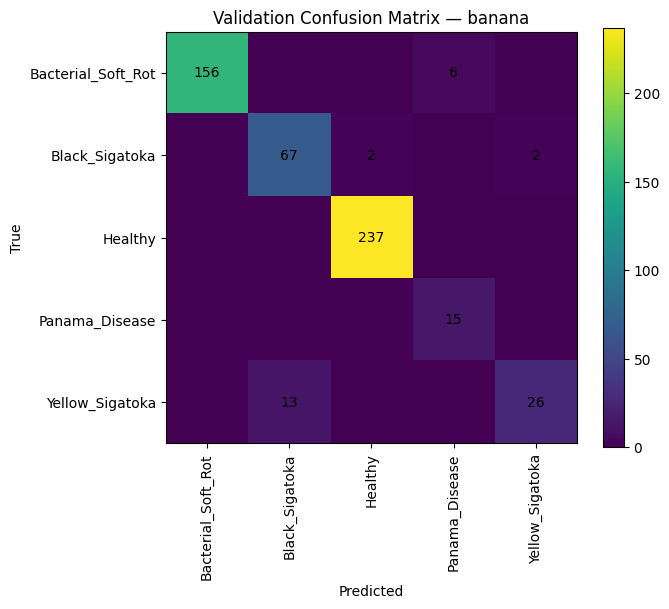

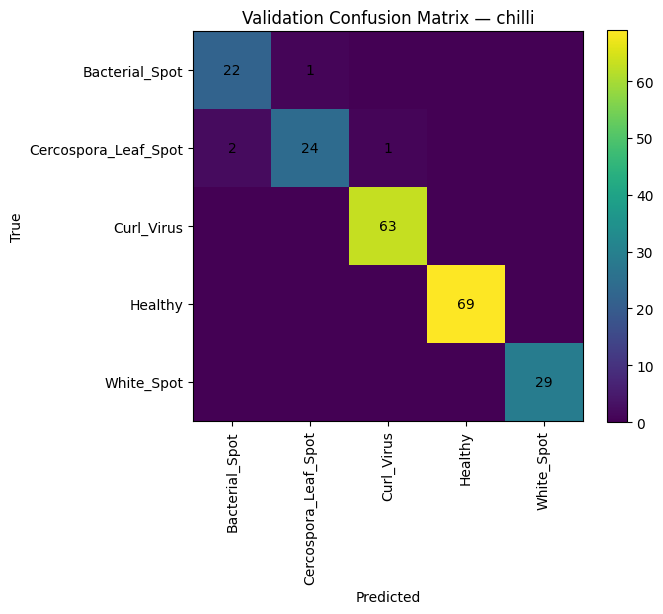

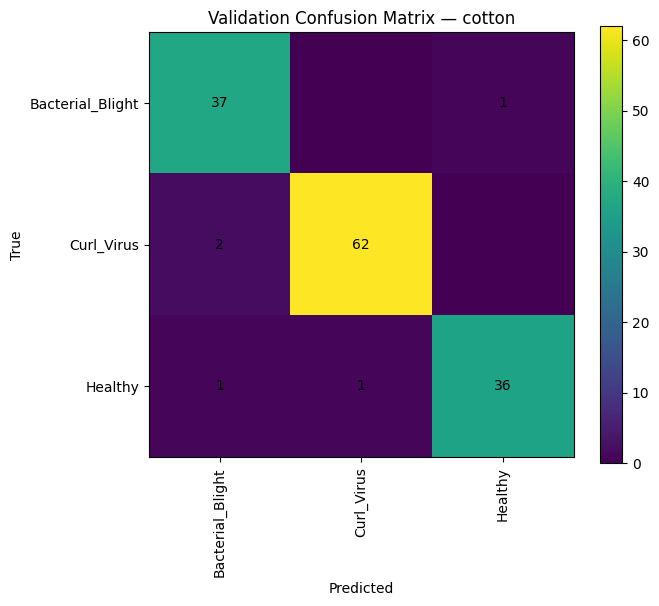

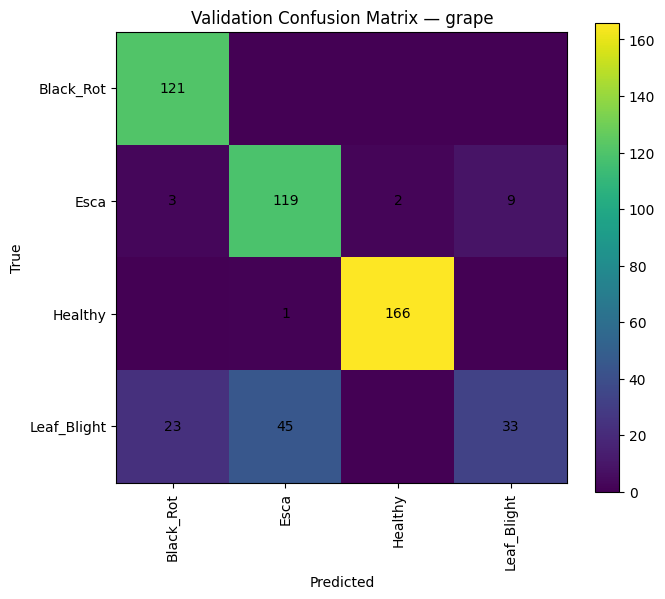

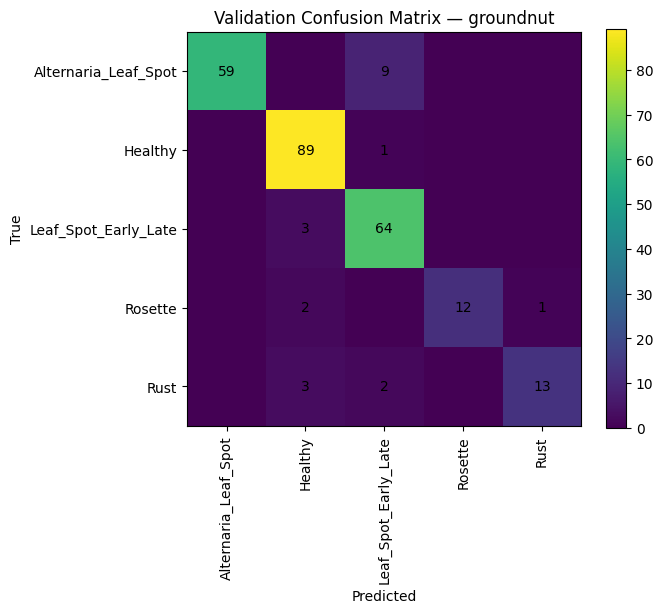

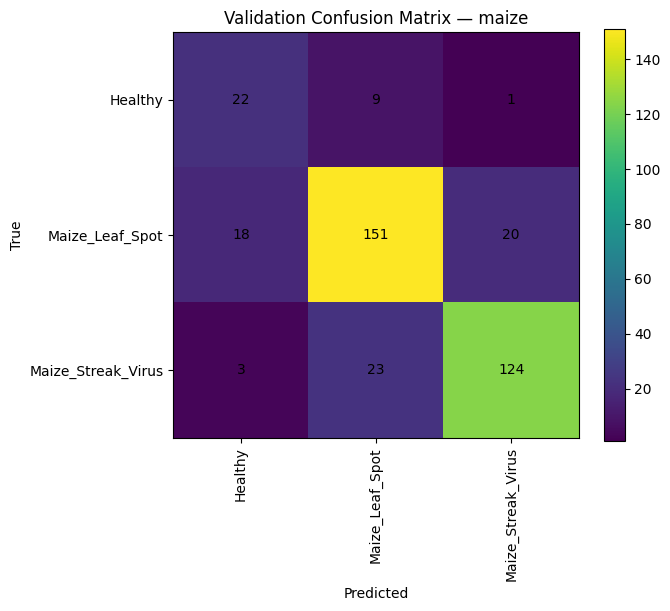

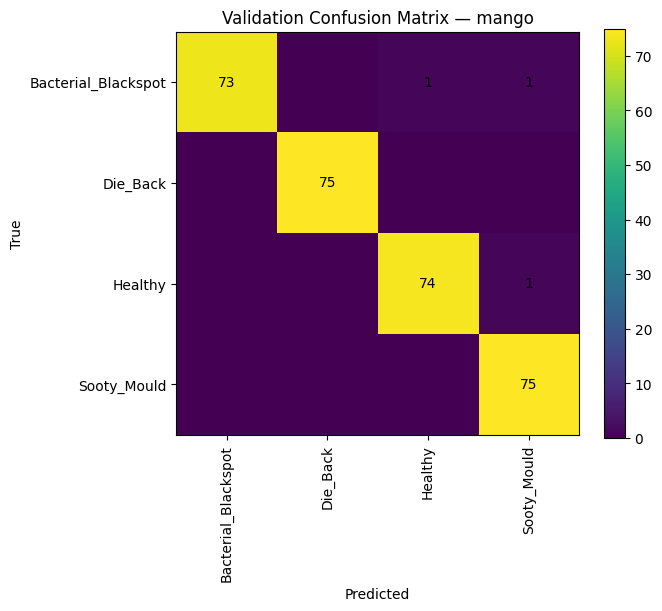

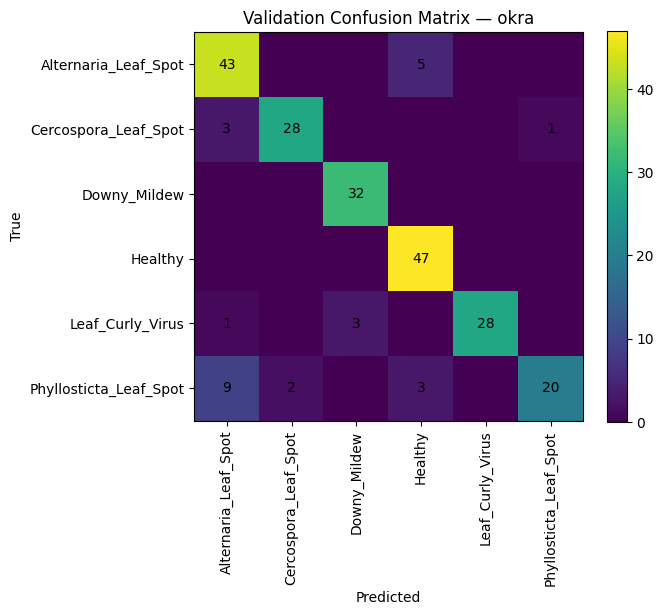

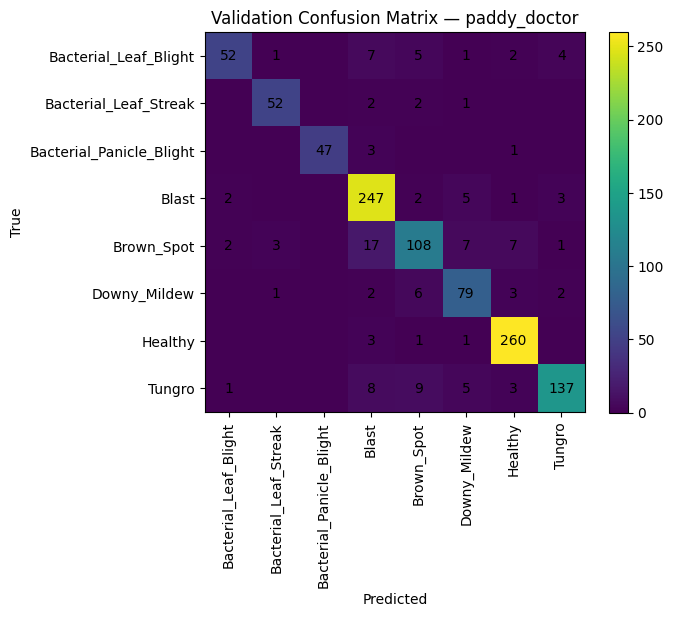

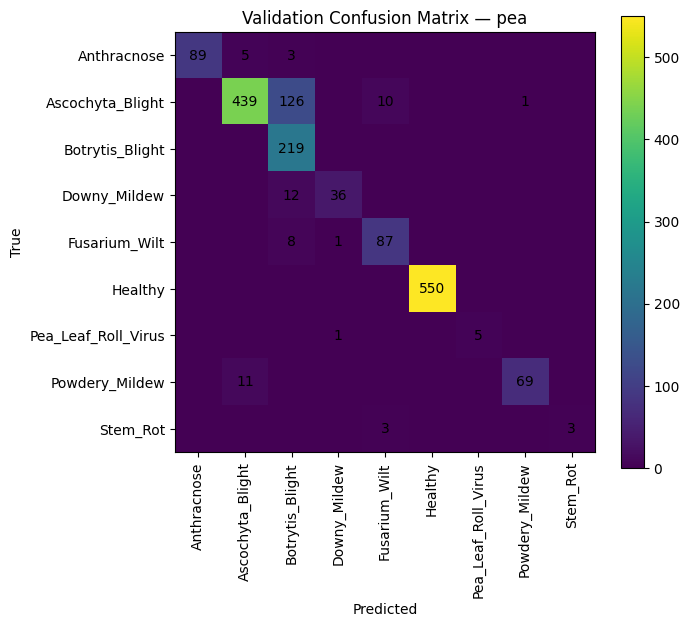

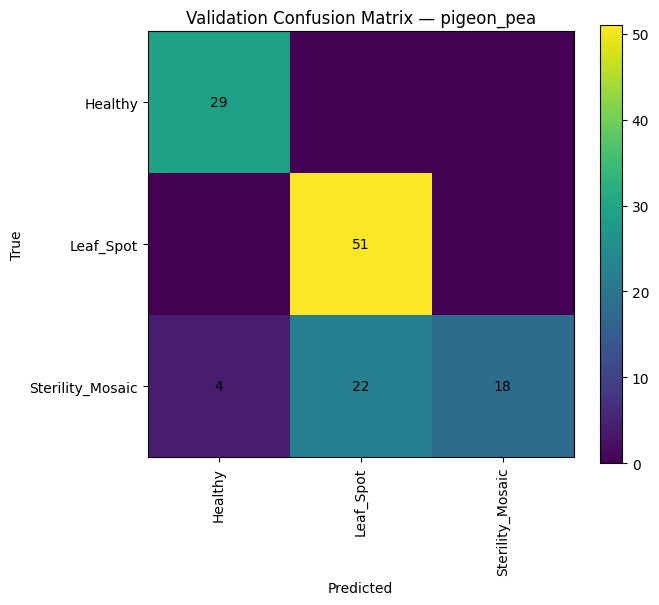

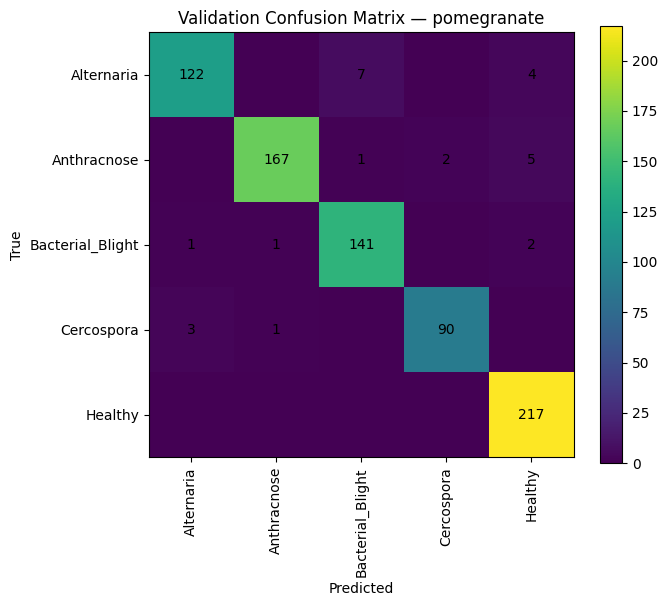

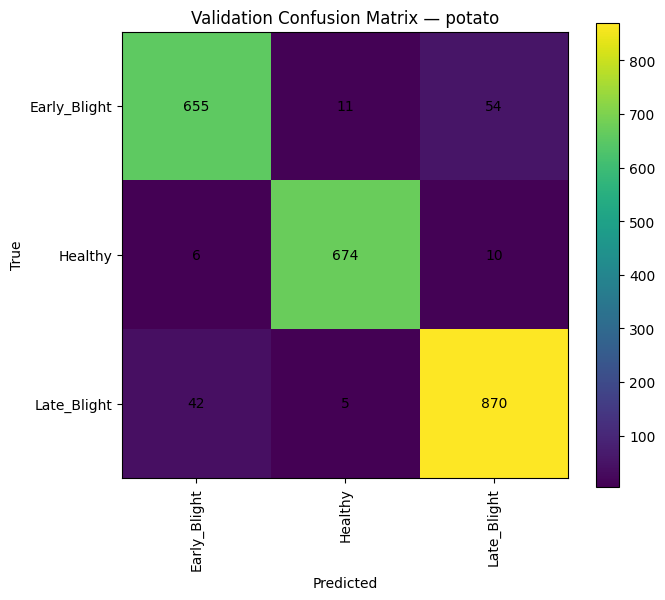

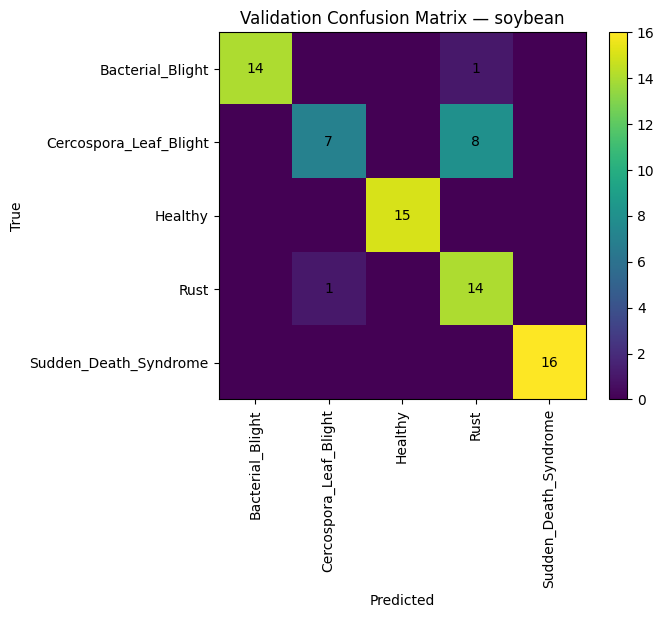

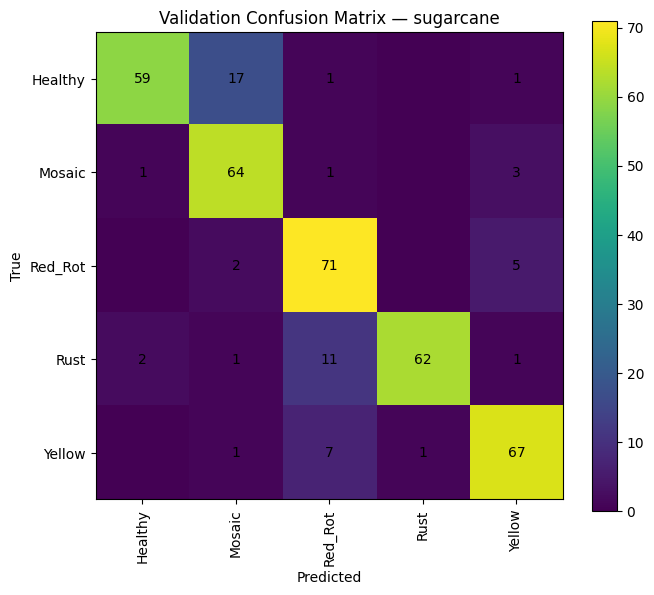

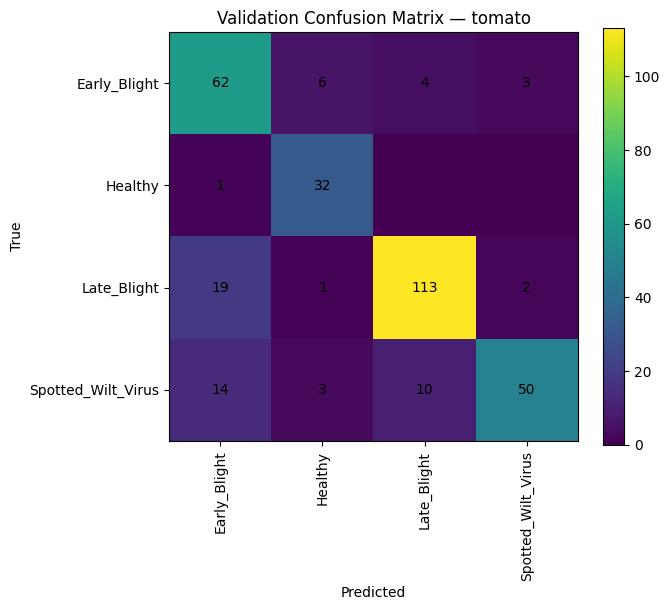

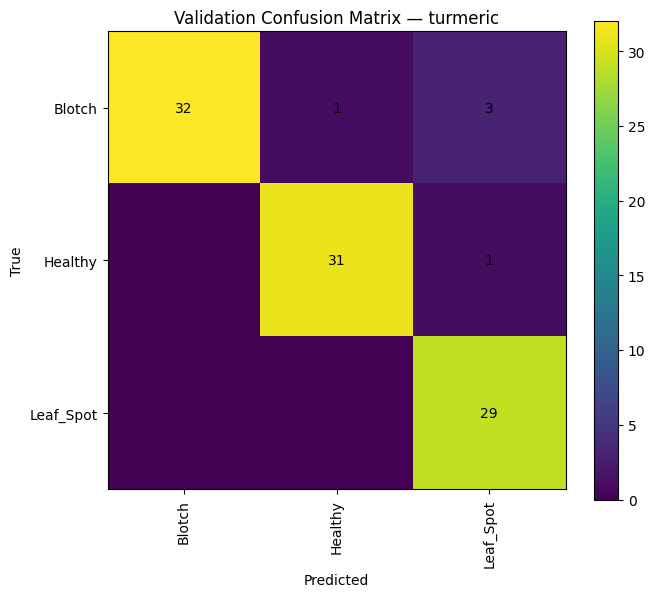

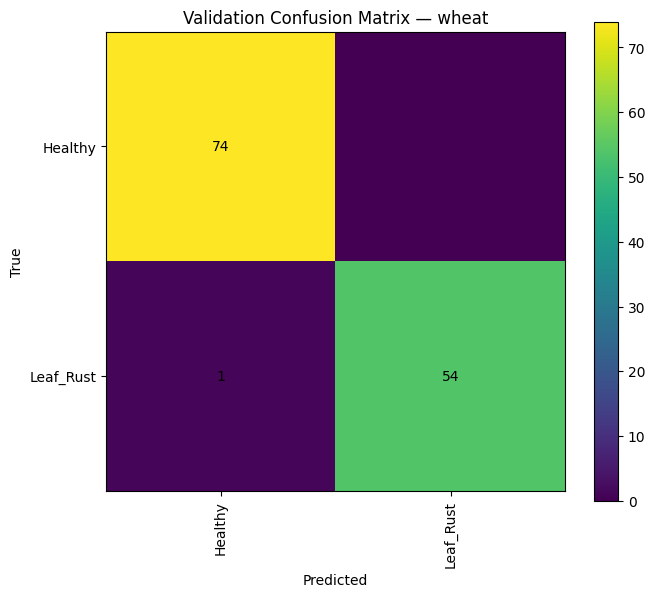

In [16]:
def plot_crop_confusion_matrix(results_df, crop):
    crop_df = results_df[results_df["crop"] == crop]
    labels = list(disease_to_index[crop].keys())

    cm = confusion_matrix(
        crop_df["true_disease"],
        crop_df["predicted_disease"],
        labels=labels,
    )

    fig, ax = plt.subplots(figsize=(max(7, len(labels) * 0.8), max(6, len(labels) * 0.7)))
    im = ax.imshow(cm)
    ax.set_title(f"Validation Confusion Matrix — {crop}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_yticklabels(labels)

    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j] != 0:
                ax.text(j, i, cm[i, j], ha="center", va="center")

    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

for crop in crops:
    plot_crop_confusion_matrix(val_results, crop)


## Incorrect predictions

This table lets us inspect where the baseline is making mistakes and how confident it was.

In [17]:
incorrect_val = val_results[~val_results["correct"]].copy()
incorrect_val = incorrect_val.sort_values("confidence", ascending=False)

print("Incorrect validation predictions:", len(incorrect_val))
display(incorrect_val.head(50))


Incorrect validation predictions: 860


,crop,true_disease,predicted_disease,true_index,predicted_index,confidence,correct
3002,potato,Late_Blight,Early_Blight,2,0,0.999947,False
571,potato,Late_Blight,Early_Blight,2,0,0.999909,False
2530,groundnut,Alternaria_Leaf_Spot,Leaf_Spot_Early_Late,0,2,0.999809,False
6845,sugarcane,Red_Rot,Yellow,2,4,0.999696,False
4060,sugarcane,Rust,Red_Rot,3,2,0.999660,False
6097,pomegranate,Alternaria,Bacterial_Blight,0,2,0.999460,False
1161,groundnut,Alternaria_Leaf_Spot,Leaf_Spot_Early_Late,0,2,0.999420,False
172,paddy_doctor,Tungro,Healthy,7,6,0.999384,False
5533,potato,Late_Blight,Early_Blight,2,0,0.999377,False
964,grape,Leaf_Blight,Black_Rot,3,0,0.999237,False


In [18]:
# Most common confusion pairs within each crop

confusion_pairs = (
    incorrect_val
    .groupby(["crop", "true_disease", "predicted_disease"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(confusion_pairs.head(30))


,crop,true_disease,predicted_disease,count
78,pea,Ascochyta_Blight,Botrytis_Blight,126
100,potato,Early_Blight,Late_Blight,54
16,grape,Leaf_Blight,Esca,45
103,potato,Late_Blight,Early_Blight,42
29,maize,Maize_Streak_Virus,Maize_Leaf_Spot,23
15,grape,Leaf_Blight,Black_Rot,23
88,pigeon_pea,Sterility_Mosaic,Leaf_Spot,22
27,maize,Maize_Leaf_Spot,Maize_Streak_Virus,20
127,tomato,Late_Blight,Early_Blight,19
26,maize,Maize_Leaf_Spot,Healthy,18


## Held-out test evaluation

The test set is loaded from the original image files using the same deterministic validation/test preprocessing: RGB → aspect-ratio-preserving `ImageOps.pad` to `128×128` → tensor → `[0,1]`.

In [19]:
class ImageFileDiseaseDataset(torch.utils.data.Dataset):
    def __init__(self, records, crop_to_index, disease_to_index):
        self.records = records
        self.crop_to_index = crop_to_index
        self.disease_to_index = disease_to_index

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        image_path, crop, disease = self.records[index]

        image = Image.open(image_path).convert("RGB")
        image = ImageOps.pad(
            image,
            (128, 128),
            color=(0, 0, 0),
        )

        image = torch.from_numpy(
            np.array(image, dtype=np.uint8)
        ).permute(2, 0, 1).float() / 255.0

        crop_label = self.crop_to_index[crop]
        disease_label = self.disease_to_index[crop][disease]

        return image, crop_label, disease_label

test_dataset = ImageFileDiseaseDataset(
    test_records,
    crop_to_index,
    disease_to_index,
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"),
)

test_accuracy, test_results = evaluate_loader(
    model,
    test_loader,
    device,
    crops,
    index_to_disease,
)

print("=" * 60)
print(f"TEST ACCURACY: {test_accuracy * 100:.2f}%")
print("Samples:", len(test_results))
print("=" * 60)


Processed 50 batches...
Processed 100 batches...
Processed 150 batches...
Processed 200 batches...
Processed 250 batches...
TEST ACCURACY: 91.30%
Samples: 9550


## Compare validation vs test

In [20]:
comparison_df = pd.DataFrame({
    "split": ["Validation", "Test"],
    "samples": [len(val_results), len(test_results)],
    "accuracy": [val_accuracy, test_accuracy],
})

display(comparison_df.style.format({"accuracy": "{:.2%}"}))


,split,samples,accuracy
0,Validation,9550,90.99%
1,Test,9550,91.30%


## Single-image inference

**Important:** because this model does not predict the crop, you must provide the crop when calling the inference function.

In [21]:
def predict_single_image(image_path, crop_name, model=model):
    """
    Predict the disease for one image when the crop is known.

    Returns a dictionary containing the crop, predicted disease,
    confidence, and the full probability distribution for that crop head.
    """

    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    if crop_name not in crop_to_index:
        raise ValueError(
            f"Unknown crop '{crop_name}'. Choose one of: {crops}"
        )

    image = Image.open(image_path).convert("RGB")
    image = ImageOps.pad(
        image,
        (128, 128),
        color=(0, 0, 0),
    )

    image = torch.from_numpy(
        np.array(image, dtype=np.uint8)
    ).permute(2, 0, 1).float() / 255.0

    image = image.unsqueeze(0).to(device)
    crop_label = torch.tensor(
        [crop_to_index[crop_name]],
        dtype=torch.long,
        device=device,
    )

    model.eval()

    with torch.inference_mode():
        outputs = model(image, crop_label)
        logits = outputs[crop_to_index[crop_name]]
            
        probabilities = torch.softmax(logits, dim=1)[0]
        confidence, prediction_index = probabilities.max(dim=0)

    prediction_index = prediction_index.item()
    confidence = confidence.item()

    disease_name = index_to_disease[crop_name][prediction_index]

    probability_table = pd.DataFrame({
        "disease": [
            index_to_disease[crop_name][i]
            for i in range(len(probabilities))
        ],
        "probability": probabilities.cpu().numpy(),
    }).sort_values("probability", ascending=False)

    return {
        "image": image_path,
        "crop": crop_name,
        "predicted_disease": disease_name,
        "confidence": confidence,
        "probabilities": probability_table.reset_index(drop=True),
    }


In [22]:
# Example usage — replace this path with an actual local image.
#
# result = predict_single_image(
#     r"D:\Intelligent_farming_system\disease_dataset\processed\banana\Healthy\example.jpg",
#     "banana",
# )
#
# print("Crop:", result["crop"])
# print("Prediction:", result["predicted_disease"])
# print(f"Confidence: {result['confidence']:.2%}")
# display(result["probabilities"].head(10))


## Save evaluation results

This saves CSV files under `disease_detection/evaluation_results/` without changing the trained model or dataset.

In [23]:
RESULTS_DIR = PROJECT_ROOT / "disease_detection" / "evaluation_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

val_results.to_csv(RESULTS_DIR / "validation_predictions.csv", index=False)
test_results.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
crop_metrics_df.to_csv(RESULTS_DIR / "validation_crop_metrics.csv", index=False)
disease_metrics_df.to_csv(RESULTS_DIR / "validation_disease_metrics.csv", index=False)

summary_df = pd.DataFrame({
    "split": ["validation", "test"],
    "samples": [len(val_results), len(test_results)],
    "accuracy": [val_accuracy, test_accuracy],
})
summary_df.to_csv(RESULTS_DIR / "summary.csv", index=False)

print("Evaluation results saved to:", RESULTS_DIR)


Evaluation results saved to: D:\Intelligent_farming_system\disease_detection\evaluation_results


## Final notes

- This notebook does **not** retrain the CNN.
- It reconstructs the exact saved architecture before loading the `.pth` state dictionary.
- Validation uses the existing cached validation images.
- Test evaluation uses the held-out test records with deterministic `ImageOps.pad` preprocessing.
- The reported split is the existing provisional stratified split. It should not be described as leakage-safe until the planned duplicate/near-duplicate/source analysis is completed.
- For real inference, the crop must currently be supplied because the trained model does not contain a crop-prediction head.